In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv(
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv"
)

test = pd.read_csv(
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv"
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()


Train shape: (1460, 81)
Test shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

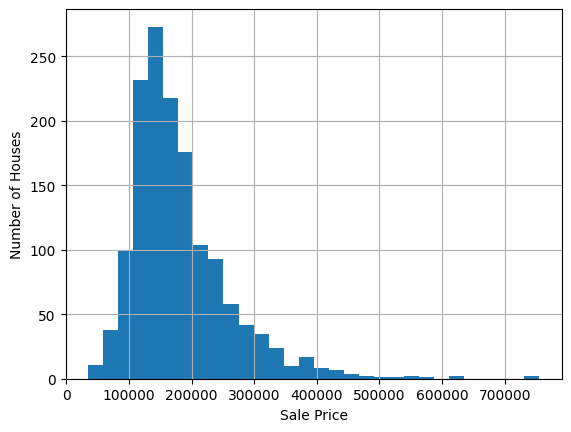

In [3]:

print(train.info())

print("\nMissing values:")
print(train.isnull().sum().sort_values(ascending=False).head(15))

print("\nHouse prices:")
print(train["SalePrice"].describe())

train["SalePrice"].hist(bins=30)
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.show()


In [4]:

y = train["SalePrice"]

X = train.drop(["SalePrice", "Id"], axis=1).copy()
X_kaggle_test = test.drop("Id", axis=1).copy()

# Feature engineering
for data in [X, X_kaggle_test]:

    data["TotalSF"] = (
        data["TotalBsmtSF"].fillna(0)
        + data["1stFlrSF"].fillna(0)
        + data["2ndFlrSF"].fillna(0)
    )

    data["TotalBathrooms"] = (
        data["FullBath"].fillna(0)
        + 0.5 * data["HalfBath"].fillna(0)
        + data["BsmtFullBath"].fillna(0)
        + 0.5 * data["BsmtHalfBath"].fillna(0)
    )

    data["HouseAge"] = data["YrSold"] - data["YearBuilt"]

    data["RemodAge"] = (
        data["YrSold"] - data["YearRemodAdd"]
    )


In [5]:

all_data = pd.concat([X, X_kaggle_test], axis=0)

# Fill missing numerical values with the median
num_cols = all_data.select_dtypes(include="number").columns

all_data[num_cols] = all_data[num_cols].fillna(
    all_data[num_cols].median()
)

# Fill missing categorical values
cat_cols = all_data.select_dtypes(exclude="number").columns

all_data[cat_cols] = all_data[cat_cols].fillna("Missing")

# Convert categorical columns into numbers
all_data = pd.get_dummies(all_data)

# Split training and test data
X = all_data.iloc[:len(train)].copy()
X_kaggle_test = all_data.iloc[len(train):].copy()

print("Training features:", X.shape)
print("Test features:", X_kaggle_test.shape)


Training features: (1460, 314)
Test features: (1459, 314)


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_log_error

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Train the model on log prices
model = GradientBoostingRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=2,
    random_state=42
)

model.fit(X_train, np.log1p(y_train))

# Predict validation prices
test_predictions = np.expm1(model.predict(X_test))

# RMSLE requires non-negative predictions
test_predictions = np.maximum(test_predictions, 0)

# Calculate RMSLE
rmsle = np.sqrt(
    mean_squared_log_error(y_test, test_predictions)
)

print("Validation RMSLE:", rmsle)


Validation RMSLE: 0.12956690656201014


In [7]:

model.fit(X, np.log1p(y))

test_predictions = np.expm1(model.predict(X_kaggle_test))

test_predictions = np.maximum(test_predictions, 0)

print("First 10 predictions:")
print(test_predictions[:10])


First 10 predictions:
[117726.03509339 161908.91848636 183237.82482916 187773.21342909
 188979.49796483 170377.00728721 175594.20825548 162908.90963426
 185514.5296997  122366.63772861]


In [8]:

submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

submission.to_csv("submission.csv", index=False)

print(submission.head())

print("Number of predictions:", len(submission))
print("Missing values:", submission["SalePrice"].isnull().sum())
print("All prices are non-negative:",
      (submission["SalePrice"] >= 0).all())


     Id      SalePrice
0  1461  117726.035093
1  1462  161908.918486
2  1463  183237.824829
3  1464  187773.213429
4  1465  188979.497965
Number of predictions: 1459
Missing values: 0
All prices are non-negative: True
